In [1]:
#导入实验相关依赖库
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

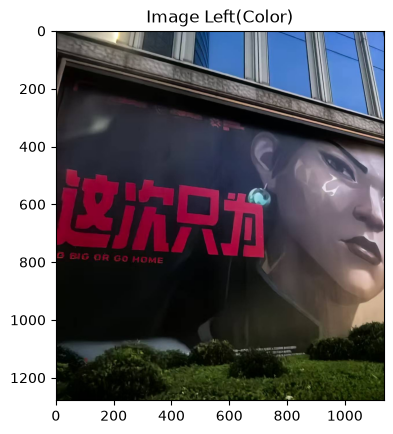

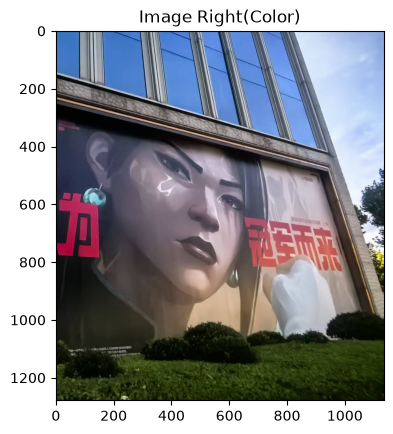

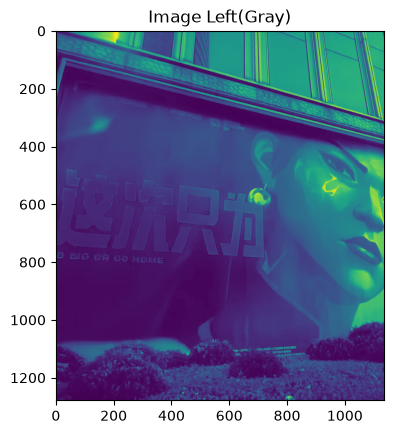

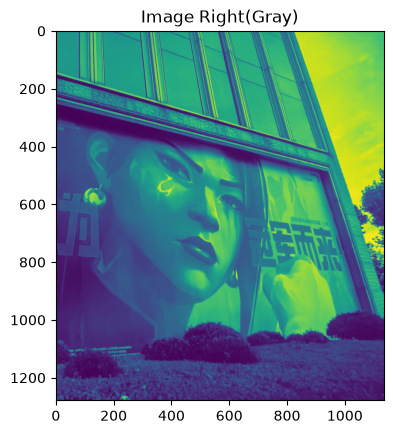

In [2]:
# 读取图像
img_a = cv2.cvtColor(cv2.imread("img/left.jpg"), cv2.COLOR_BGR2RGB)
plt.imshow(img_a)
plt.title('Image Left(Color)')
plt.savefig('result/original_left.jpg')
plt.show()

img_b = cv2.cvtColor(cv2.imread("img/right.jpg"), cv2.COLOR_BGR2RGB)
plt.imshow(img_b)
plt.title('Image Right(Color)')
plt.savefig('result/original_right.jpg')
plt.show()

# 将图像转换为灰度图
gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_a)
plt.title('Image Left(Gray)')
plt.savefig('result/gray_left.jpg')
plt.show()

gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_b)
plt.title('Image Right(Gray)')
plt.savefig('result/gray_right.jpg')
plt.show()

In [3]:
# 创建SIFT特征检测器
sift = cv2.SIFT_create()

# 检测关键点并计算描述子
kp_a, des_a = sift.detectAndCompute(img_a, None)
kp_b, des_b = sift.detectAndCompute(img_b, None)

# 使用FLANN进行特征匹配
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)# 检查次数越多，匹配越准确但速度越慢

flann = cv2.FlannBasedMatcher(index_params, search_params)

matches = flann.knnMatch(des_a, des_b, k=2)# k=2表示每个特征点返回2个最佳匹配

# Lowe's 比率测试(筛选优质匹配点)
good_matches = []

for m, n in matches:
    if m.distance < 0.7 * n.distance:# 比率阈值通常取0.7-0.8
        good_matches.append(m)

# 输出匹配统计信息
print("=== 特征匹配统计 ===")
print(f"初始匹配点对数: {len(matches)}")
print(f"筛选后优质匹配点对数: {len(good_matches)}")
print(f"过滤掉的匹配点对数: {len(matches) - len(good_matches)}")
print(f"优质匹配点比例: {len(good_matches)/len(matches):.2%}")

=== 特征匹配统计 ===
初始匹配点对数: 1944
筛选后优质匹配点对数: 979
过滤掉的匹配点对数: 965
优质匹配点比例: 50.36%


左图特征点数量： 1944
右图特征点数量： 3138


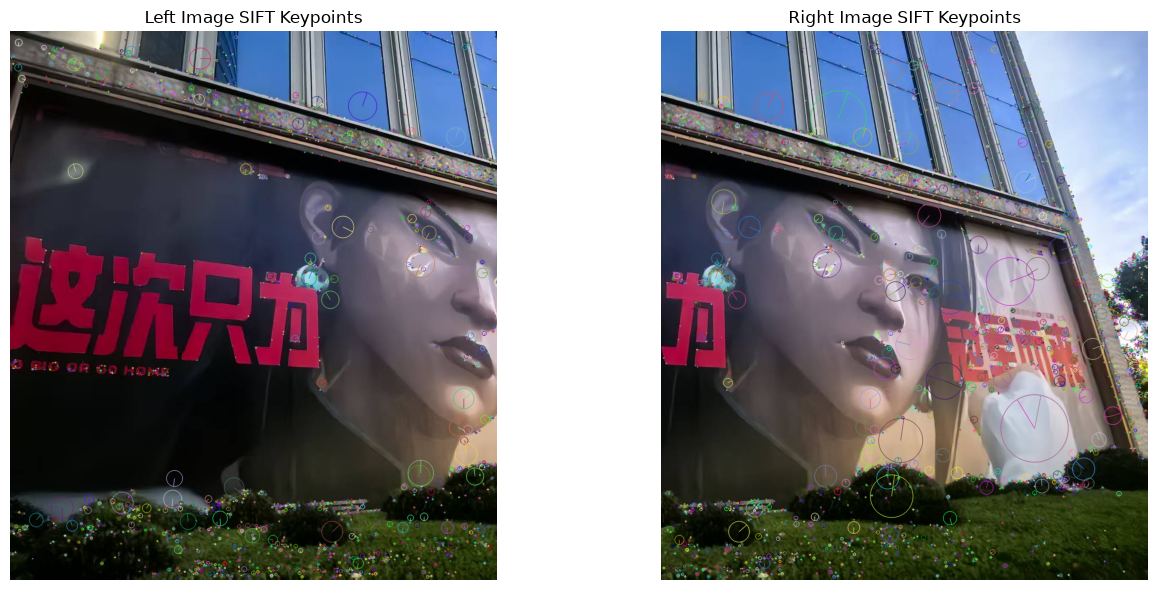

In [4]:
# SIFT 特征点可视化
vis_a = cv2.drawKeypoints(
    img_a, kp_a, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
vis_b = cv2.drawKeypoints(
    img_b, kp_b, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

print("左图特征点数量：", len(kp_a))
print("右图特征点数量：", len(kp_b))

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(vis_a)
plt.title("Left Image SIFT Keypoints")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vis_b)
plt.title("Right Image SIFT Keypoints")
plt.axis("off")

plt.tight_layout()
plt.savefig("result/SIFT Keypoints.jpg", dpi=200)
plt.show()

阈值=0.6, 匹配点=950, 内点=945, 内点率=99.47%
阈值=0.7, 匹配点=979, 内点=961, 内点率=98.16%
阈值=0.8, 匹配点=1037, 内点=968, 内点率=93.35%
阈值=0.9, 匹配点=1228, 内点=976, 内点率=79.48%


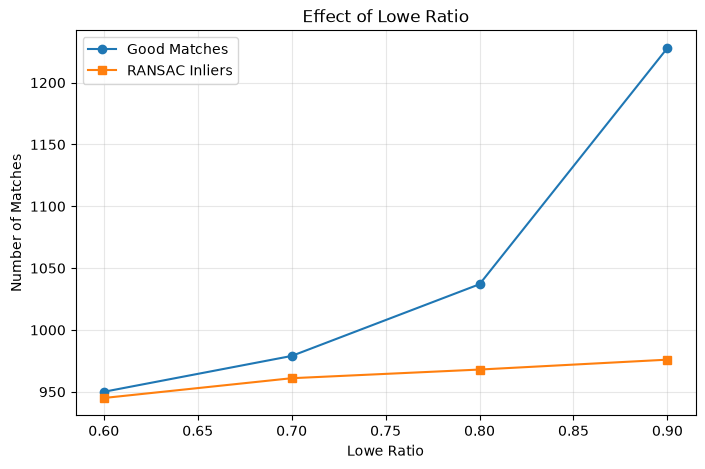

In [5]:
# Lowe 比率阈值对比
ratios = [0.6, 0.7, 0.8, 0.9]
match_counts = []
inlier_counts = []

for ratio in ratios:
    good = []

    for pair in matches:
        if len(pair) == 2:
            m, n = pair
            if m.distance < ratio * n.distance:
                good.append(m)

    match_counts.append(len(good))

    if len(good) < 4:
        inlier_counts.append(0)
        continue

    src = np.float32([
        kp_b[m.trainIdx].pt for m in good
    ]).reshape(-1, 1, 2)

    dst = np.float32([
        kp_a[m.queryIdx].pt for m in good
    ]).reshape(-1, 1, 2)

    H_tmp, mask_tmp = cv2.findHomography(
        src, dst, cv2.RANSAC, 5.0
    )

    inliers = int(mask_tmp.sum()) if mask_tmp is not None else 0
    inlier_counts.append(inliers)

    print(
        f"阈值={ratio}, 匹配点={len(good)}, "
        f"内点={inliers}, 内点率={inliers / len(good):.2%}"
    )

plt.figure(figsize=(8, 5))
plt.plot(ratios, match_counts, "o-", label="Good Matches")
plt.plot(ratios, inlier_counts, "s-", label="RANSAC Inliers")

plt.xlabel("Lowe Ratio")
plt.ylabel("Number of Matches")
plt.title("Effect of Lowe Ratio")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("result/Lowe Ratio Comparison.jpg", dpi=200)
plt.show()

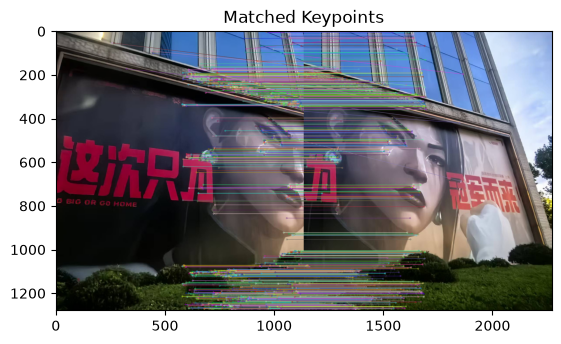

In [4]:
# 绘制匹配的SIFT关键点
matched_keypoints_img = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b, good_matches,
    None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.imshow(matched_keypoints_img)
plt.title('Matched Keypoints')
plt.savefig('result/Matched Keypoints.jpg')
plt.show()

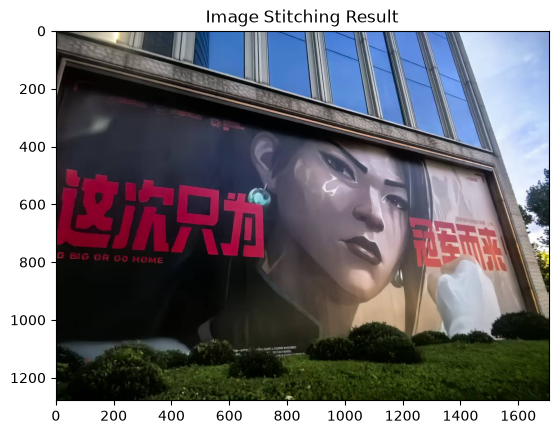

In [9]:
# 提取匹配点的坐标
src_pts = np.float32([kp_b[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_a[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

# 使用RANSAC算法估计单应矩阵
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

# 获取输入图像尺寸
h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

# 计算图像变换后的四个角坐标
pts = np.float32([[0, 0], [0, h_b], [w_b, h_b], [w_b, 0]]).reshape(-1, 1, 2)
dst_corners = cv2.perspectiveTransform(pts, H)

# 确定拼接后图像的最终尺寸
all_corners = np.concatenate([dst_corners, np.float32([[0,0], [w_a,0], [w_a,h_a], [0,h_a]]).reshape(-1,1,2)], axis=0)
[x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() + 0.5)
[x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

# 创建平移矩阵，确保所有像素都在可视区域内
translation_matrix = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], dtype=np.float32)

# 对图像进行透视变换和平移
fus_img = cv2.warpPerspective(
    img_b,
    translation_matrix @ H, 
    (x_max - x_min, y_max - y_min)
)

# 将图像复制到拼接结果的对应位置
fus_img[-y_min : h_a - y_min, -x_min : w_a - x_min] = img_a

plt.imshow(fus_img)
plt.title('Image Stitching Result')
plt.savefig('result/Image Stitching Result.jpg', dpi=300, bbox_inches='tight')
plt.show()

阈值=2.0, 内点数量=959, 内点率=97.96%, 重投影RMSE=0.154px
阈值=3.0, 内点数量=959, 内点率=97.96%, 重投影RMSE=0.154px
阈值=5.0, 内点数量=961, 内点率=98.16%, 重投影RMSE=0.221px
阈值=8.0, 内点数量=961, 内点率=98.16%, 重投影RMSE=0.221px


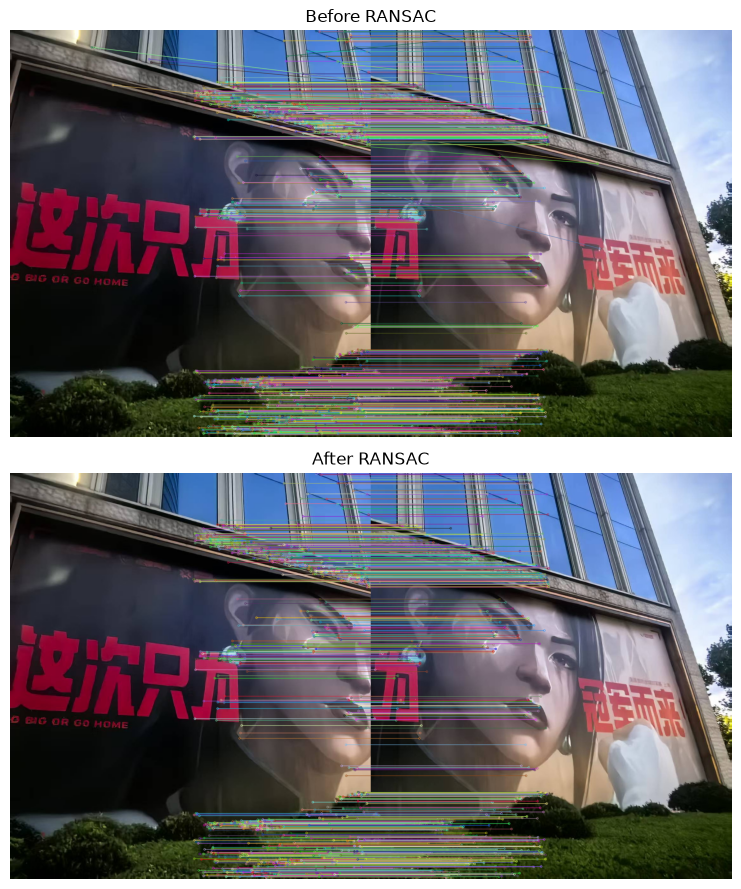

In [8]:
# RANSAC 重投影阈值对比
thresholds = [2.0, 3.0, 5.0, 8.0]

# 提取匹配点坐标
src_pts = np.float32([
    kp_b[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

dst_pts = np.float32([
    kp_a[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

# 计算原始 RANSAC 结果
H, mask = cv2.findHomography(
    src_pts, dst_pts, cv2.RANSAC, 5.0
)

for t in thresholds:
    H_tmp, mask_tmp = cv2.findHomography(
        src_pts, dst_pts, cv2.RANSAC, t
    )

    if H_tmp is None or mask_tmp is None:
        print(f"阈值={t}, 估计失败")
        continue

    inliers = int(mask_tmp.sum())
    total = len(good_matches)

    projected = cv2.perspectiveTransform(src_pts, H_tmp)
    errors = np.linalg.norm(
        projected.reshape(-1, 2) - dst_pts.reshape(-1, 2),
        axis=1
    )
    rmse = np.sqrt(np.mean(errors[mask_tmp.ravel() > 0] ** 2))

    print(
        f"阈值={t}, 内点数量={inliers}, "
        f"内点率={inliers / total:.2%}, "
        f"重投影RMSE={rmse:.3f}px"
    )

# 原始匹配与 RANSAC 内点对比
before = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

after = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b,
    good_matches, None,
    matchesMask=mask.ravel().tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 9))

plt.subplot(2, 1, 1)
plt.imshow(before)
plt.title("Before RANSAC")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(after)
plt.title("After RANSAC")
plt.axis("off")

plt.tight_layout()
plt.savefig("result/RANSAC Comparison.jpg", dpi=200)
plt.show()